<a href="https://colab.research.google.com/github/3B232056/2026_DL_hws/blob/main/hw4_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

匯入套件

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import SGD, Adam

In [3]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1308s 8us/step


#資料預處理

*  訓練/測試資料形狀





In [47]:
print("訓練資料筆數:", len(x_train))
print("測試資料筆數:", len(x_test))

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


label_dict = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

訓練資料筆數: 50000
測試資料筆數: 10000
x_train: (50000, 32, 32, 3)
y_train: (50000, 1)
x_test: (10000, 32, 32, 3)
y_test: (10000, 1)


*  訓練資料圖片

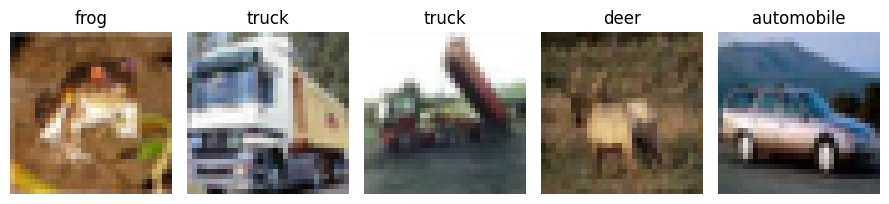

In [48]:
plt.figure(figsize=(9, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i])
    label_index = int(y_train[i][0])
    plt.title(label_dict[label_index])
    plt.axis("off")
plt.tight_layout()
plt.show()

*  拉平常模化、one-hot-encoding

In [11]:
x_train_normalize = x_train / 255
x_test_normalize = x_test / 255

y_train_OneHot = to_categorical(y_train, 10)
y_test_OneHot = to_categorical(y_test, 10)

In [12]:
print(x_train_normalize.shape)
print(x_test_normalize.shape)

print(y_train_OneHot.shape)
print(y_test_OneHot.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)
(50000, 10)
(10000, 10)


#建立神經網路模型

In [16]:
model = Sequential()

In [17]:
#第一層：卷積層，16 個 Filter，尺寸 (3,3)
model.add(Conv2D(16, (3, 3), padding='same',
                 input_shape=(32, 32, 3),
                 activation='relu'))

In [18]:
# 第二層：卷積層，16 個 Filter，尺寸 (3,3)
model.add(Conv2D(16, (3, 3), padding='same',
                 activation='relu'))

In [19]:
# 第三層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [20]:
# 第四層：卷積層，32 個 Filter，尺寸 (3,3)
model.add(Conv2D(32, (3, 3), padding='same',
                 activation='relu'))

In [21]:
# 第五層：卷積層，32 個 Filter，尺寸 (3,3)
model.add(Conv2D(32, (3, 3), padding='same',
                 activation='relu'))

In [22]:
# 第六層：池化層，尺寸 (2,2)
model.add(MaxPool2D(pool_size=(2, 2)))

In [23]:
# 第七層：拉平層
model.add(Flatten())

In [24]:
# 第八層：全連接層
model.add(Dense(10, activation='softmax'))

In [25]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,146 (145.10 KB)

 Trainable params: 37,146 (145.10 KB)

 Non-trainable params: 0 (0.00 B)

#每一層參數個數


*  第一層:(3×3×3+1)×16=448
*  第二層:(3×3×16+1)×16=2320
*  第四層:(3×3×16+1)×32=4640
*  第五層:(3×3×32+1)×32=9248
*  最後全連接層:(2048+1)×10=20490




#input shape及每一層的output shape
*  批次訓練時的input shape:(None, 32, 32, 3)
*  第一層output shape :(None, 32, 32, 16)
*  第二層output shape :(None, 32, 32, 16)
*  第三層output shape :(None, 16, 16, 16)
*  第四層output shape :(None, 16, 16, 32)
*  第五層output shape :(None, 16, 16, 32)
*  第六層output shape :(None, 8, 8, 32)
*  拉平層output shape :(None, 2048)  
*  全連接層output shape :(None, 10)   

#訓練神經網路模型

In [26]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

In [28]:
train_history = model.fit(x=x_train_normalize,
              y=y_train_OneHot,
              validation_split=0.2,
              epochs=20,
              batch_size=128,
              verbose=2)

Epoch 1/20
313/313 - 61s - 194ms/step - accuracy: 0.7744 - loss: 0.6561 - val_accuracy: 0.7103 - val_loss: 0.8666
Epoch 2/20
313/313 - 62s - 197ms/step - accuracy: 0.7821 - loss: 0.6335 - val_accuracy: 0.7144 - val_loss: 0.8594
Epoch 3/20
313/313 - 69s - 222ms/step - accuracy: 0.7876 - loss: 0.6128 - val_accuracy: 0.7103 - val_loss: 0.8796
Epoch 4/20
313/313 - 59s - 188ms/step - accuracy: 0.7945 - loss: 0.5928 - val_accuracy: 0.7033 - val_loss: 0.9040
Epoch 5/20
313/313 - 81s - 258ms/step - accuracy: 0.8012 - loss: 0.5795 - val_accuracy: 0.7070 - val_loss: 0.8952
Epoch 6/20
313/313 - 82s - 262ms/step - accuracy: 0.8072 - loss: 0.5640 - val_accuracy: 0.7098 - val_loss: 0.8822
Epoch 7/20
313/313 - 84s - 269ms/step - accuracy: 0.8109 - loss: 0.5479 - val_accuracy: 0.7018 - val_loss: 0.9315
Epoch 8/20
313/313 - 83s - 264ms/step - accuracy: 0.8178 - loss: 0.5257 - val_accuracy: 0.7017 - val_loss: 0.9293
Epoch 9/20
313/313 - 60s - 193ms/step - accuracy: 0.8225 - loss: 0.5144 - val_accuracy: 

#input shape及每一層的output shape
*  批次訓練時的input shape:(128, 32, 32, 3)
*  第一層output shape :(128, 32, 32, 16)
*  第二層output shape :(128, 32, 32, 16)
*  第三層output shape :(128, 16, 16, 16)
*  第四層output shape :(128, 16, 16, 32)
*  第五層output shape :(128, 16, 16, 32)
*  第六層output shape :(128, 8, 8, 32)
*  拉平層output shape :(128, 2048)  
*  全連接層output shape :(128, 10)   

In [29]:
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

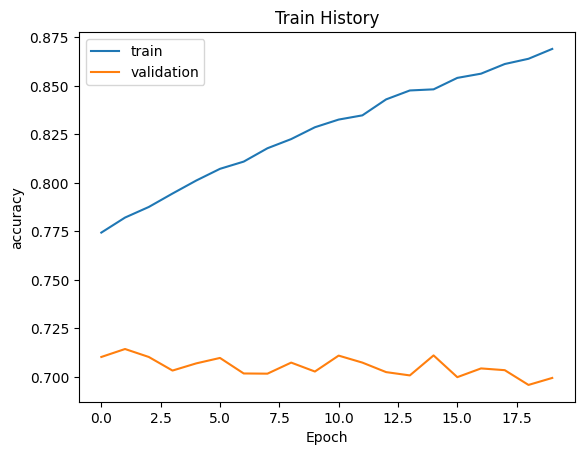

In [30]:
show_train_history(train_history,'accuracy','val_accuracy')

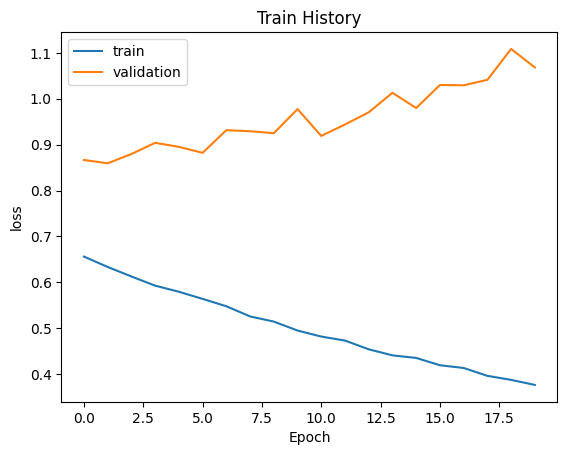

In [31]:
show_train_history(train_history,'loss','val_loss')

#結果:這兩張圖有明顯過度擬合的現象

#評估模型準確率

In [32]:
scores = model.evaluate(x_test_normalize,y_test_OneHot)

print("Loss =", scores[0])
print("正確率 =", scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7046 - loss: 1.0693
Loss = 1.0693364143371582
正確率 = 0.7045999765396118


#進行預測

In [39]:
y_pred_prob = model.predict(x_test_normalize)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test_OneHot, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


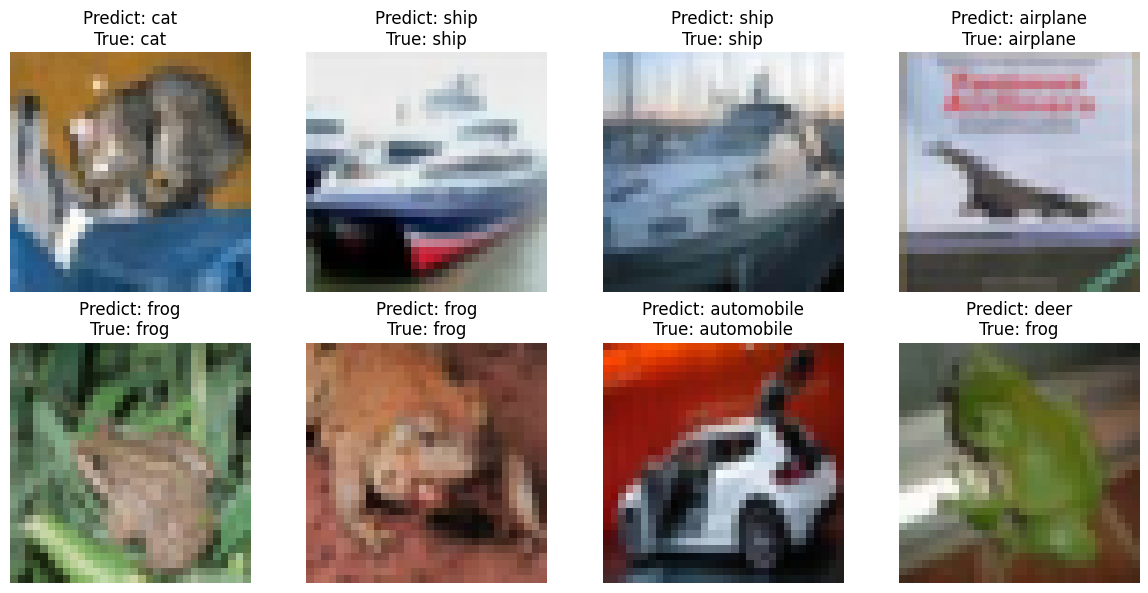

In [53]:
# 顯示 8 張測試圖片；標題為標籤名稱
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Predict: {label_dict[y_pred[i]]}\n"
        f"True: {label_dict[y_true[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

#以混淆矩陣(Confusion matrix)呈現預測結果

In [44]:
cm = pd.crosstab(y_true,y_pred,rownames=['label'],colnames=['predict'])
print(cm)

predict    0    1    2    3    4    5    6    7    8    9
label                                                    
0        723   31   57   26   30    4   15   26   56   32
1         28  822    6   10    7    9    5    5   14   94
2         63   12  538   73  119   57   77   44   11    6
3         34   10   54  556   76  159   58   35    8   10
4          9    3   63   71  695   33   46   67    8    5
5         12    6   43  216   54  575   22   60    6    6
6          5    4   44   86   49   20  777    6    4    5
7         12    5   27   45   84   43    9  765    4    6
8         62   43   16   20   14    5    4    7  800   29
9         30   79    9   14    9    8    9   30   17  795


In [45]:
# 建立 DataFrame
df = pd.DataFrame({
    'label': y_true,
    'predict': y_pred
})

# 顯示前 10 筆測試資料
df[:10]

,label,predict
0,3,3
1,8,8
2,8,8
3,0,0
4,6,6
5,6,6
6,1,1
7,6,4
8,3,3
9,1,1


In [46]:
df[(df.label==4)&(df.predict==1)]  # 真實標籤為4，卻預測為1

,label,predict
1049,4,1
3240,4,1
5838,4,1


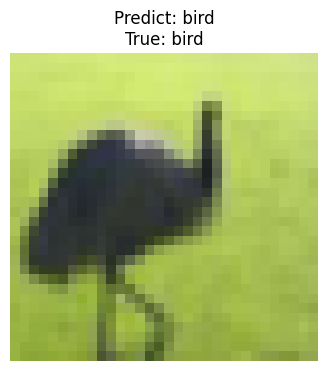

In [59]:
#預測正確
idx = 123

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

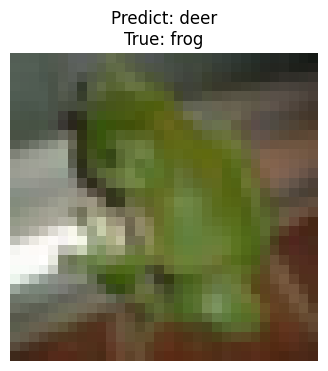

In [58]:
#預測錯誤
idx = 7

plt.figure(figsize=(4,4))
plt.imshow(x_test[idx])

plt.title(
    f"Predict: {label_dict[y_pred[idx]]}\n"
    f"True: {label_dict[y_true[idx]]}"
)

plt.axis("off")
plt.show()

#儲存完整模型

In [60]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [61]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [62]:
model.save('my_cnn_model_hw4-1.keras')

#interact_manual

In [63]:
from ipywidgets import interact_manual

In [64]:
def test(測試編號):

    plt.figure(figsize=(4,4))
    plt.imshow(x_test[測試編號])
    plt.axis('off')
    plt.show()

    pred_class = y_pred[測試編號]
    actual_class = y_true[測試編號]

    print('神經網路判斷為:',
          label_dict[pred_class],
          f'({pred_class})')

    print('實際答案為:',
          label_dict[actual_class],
          f'({actual_class})')

interact_manual(test, 測試編號=(0,9999))

interactive(children=(IntSlider(value=4999, description='測試編號', max=9999), Button(description='Run Interact', …

<function __main__.test(測試編號)>